<a href="https://colab.research.google.com/github/shiv2899/deforestation-detection-sentinel2-unet/blob/main/01_deforestation_setup_and_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

!pip install -q segmentation-models-pytorch rasterio folium geopandas

from google.colab import drive
drive.mount('/content/drive')

import os
base = "/content/drive/MyDrive/deforestation-project"
os.makedirs(f"{base}/data", exist_ok=True)
os.makedirs(f"{base}/models", exist_ok=True)
os.makedirs(f"{base}/outputs", exist_ok=True)
print("Folders ready:", base)

GPU: True Tesla T4
Mounted at /content/drive
Folders ready: /content/drive/MyDrive/deforestation-project


In [2]:
import os
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_1e6fcba8e7e7896dca414234a831db22'

%cd /content/drive/MyDrive/deforestation-project/data
!kaggle datasets download -d quadeer15sh/augmented-forest-segmentation --unzip
!ls -lh

/content/drive/MyDrive/deforestation-project/data
Dataset URL: https://www.kaggle.com/datasets/quadeer15sh/augmented-forest-segmentation
License(s): other
100% 172M/172M [00:04<00:00, 37.5MB/s]

total 193K
drwx------ 3 root root 4.0K Nov 17 16:56 'Forest Segmented'
-rw------- 1 root root 189K Nov 17 16:58  meta_data.csv


Total Images: 5108 Total Masks: 5108


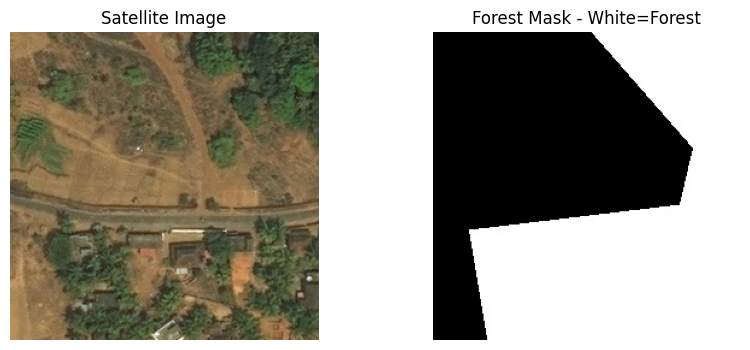

In [3]:
import glob, random
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/drive/MyDrive/deforestation-project/data/Forest Segmented/Forest Segmented"
imgs = sorted(glob.glob(f"{base}/images/*.jpg"))
masks = sorted(glob.glob(f"{base}/masks/*.jpg"))
print("Total Images:", len(imgs), "Total Masks:", len(masks))

idx = random.randint(0, len(imgs)-1)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(Image.open(imgs[idx])); plt.title("Satellite Image"); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(Image.open(masks[idx])); plt.title("Forest Mask - White=Forest"); plt.axis('off')
plt.show()

In [4]:
import glob, os, torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp

base = "/content/drive/MyDrive/deforestation-project/data/Forest Segmented/Forest Segmented"
imgs = sorted(glob.glob(f"{base}/images/*.jpg"))
masks = sorted(glob.glob(f"{base}/masks/*.jpg"))

class ForestDataset(Dataset):
    def __init__(self, img_paths, mask_paths):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
    def __len__(self):
        return len(self.img_paths)
    def __getitem__(self, idx):
        img = np.array(Image.open(self.img_paths[idx]).resize((256,256))) / 255.0
        mask = np.array(Image.open(self.mask_paths[idx]).convert("L").resize((256,256))) / 255.0
        mask = (mask > 0.5).astype(np.float32)
        img = torch.from_numpy(img).permute(2,0,1).float()
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return img, mask

train_imgs, val_imgs, train_masks, val_masks = train_test_split(imgs, masks, test_size=0.2, random_state=42)
train_loader = DataLoader(ForestDataset(train_imgs, train_masks), batch_size=16, shuffle=True)
val_loader = DataLoader(ForestDataset(val_imgs, val_masks), batch_size=16)
print(f"Train: {len(train_imgs)}, Val: {len(val_imgs)}")

device = "cuda" if torch.cuda.is_available() else "cpu"
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)
print("Model ready on:", device)

Train: 4086, Val: 1022


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model ready on: cuda


In [5]:
import torch.nn as nn
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.BCEWithLogitsLoss()
best_iou = 0

for epoch in range(10):
    model.train()
    train_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    inter, union = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            pred = (torch.sigmoid(model(x)) > 0.5).float()
            inter += (pred * y).sum().item()
            union += ((pred + y) > 0).sum().item()
    iou = inter / (union + 1e-7)
    print(f"Epoch {epoch+1}/10 | Loss: {train_loss/len(train_loader):.4f} | Val IoU: {iou:.4f}")
    if iou > best_iou:
        best_iou = iou
        torch.save(model.state_dict(), "/content/drive/MyDrive/deforestation-project/models/best_unet.pth")
        print(f"  -> Best model saved! IoU: {best_iou:.4f}")

print(f"Training Done! Best IoU: {best_iou:.4f}")

Epoch 1/10 | Loss: 0.4595 | Val IoU: 0.7343
  -> Best model saved! IoU: 0.7343
Epoch 2/10 | Loss: 0.3711 | Val IoU: 0.7688
  -> Best model saved! IoU: 0.7688
Epoch 3/10 | Loss: 0.3196 | Val IoU: 0.7284
Epoch 4/10 | Loss: 0.2654 | Val IoU: 0.7338
Epoch 5/10 | Loss: 0.2086 | Val IoU: 0.7558
Epoch 6/10 | Loss: 0.1863 | Val IoU: 0.7691
  -> Best model saved! IoU: 0.7691
Epoch 7/10 | Loss: 0.1630 | Val IoU: 0.7696
  -> Best model saved! IoU: 0.7696
Epoch 8/10 | Loss: 0.1433 | Val IoU: 0.7641
Epoch 9/10 | Loss: 0.1234 | Val IoU: 0.7156
Epoch 10/10 | Loss: 0.1119 | Val IoU: 0.7713
  -> Best model saved! IoU: 0.7713
Training Done! Best IoU: 0.7713


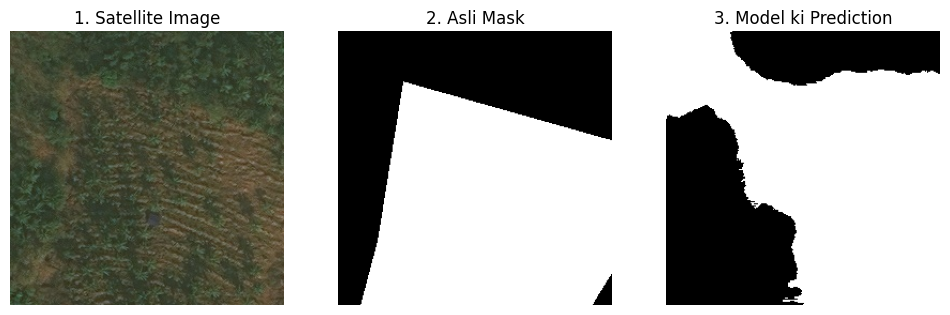

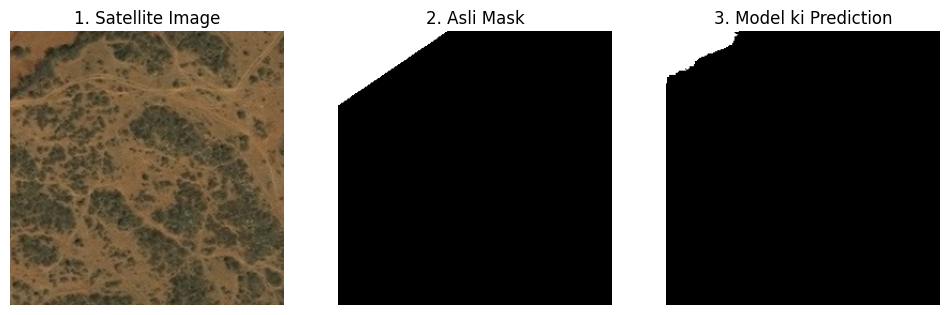

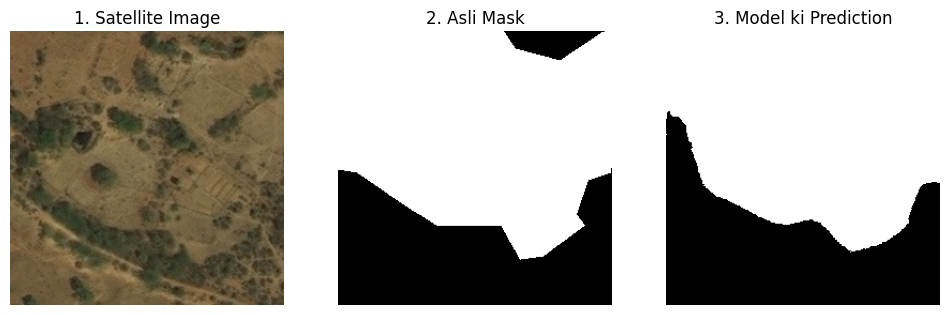

In [6]:
import glob, random, torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Best model load karo
model.load_state_dict(torch.load("/content/drive/MyDrive/deforestation-project/models/best_unet.pth", map_location=device))
model.eval()

base = "/content/drive/MyDrive/deforestation-project/data/Forest Segmented/Forest Segmented"
imgs = sorted(glob.glob(f"{base}/images/*.jpg"))
masks = sorted(glob.glob(f"{base}/masks/*.jpg"))

# 3 random photo dikhao
for i in range(3):
    idx = random.randint(0, len(imgs)-1)
    img_np = np.array(Image.open(imgs[idx]).resize((256,256))) / 255.0
    true_mask = np.array(Image.open(masks[idx]).convert("L").resize((256,256))) / 255.0
    true_mask = (true_mask > 0.5)

    x = torch.from_numpy(img_np).permute(2,0,1).unsqueeze(0).float().to(device)
    with torch.no_grad():
        pred = (torch.sigmoid(model(x)) > 0.5).cpu().numpy()[0,0]

    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.imshow(img_np); plt.title("1. Satellite Image"); plt.axis('off')
    plt.subplot(1,3,2); plt.imshow(true_mask, cmap='Greys'); plt.title("2. Asli Mask"); plt.axis('off')
    plt.subplot(1,3,3); plt.imshow(pred, cmap='Greys'); plt.title("3. Model ki Prediction"); plt.axis('off')
    plt.show()

Forest in 2020: 65536 pixels
Forest in 2024: 55536 pixels
Deforested Area: 15.26%


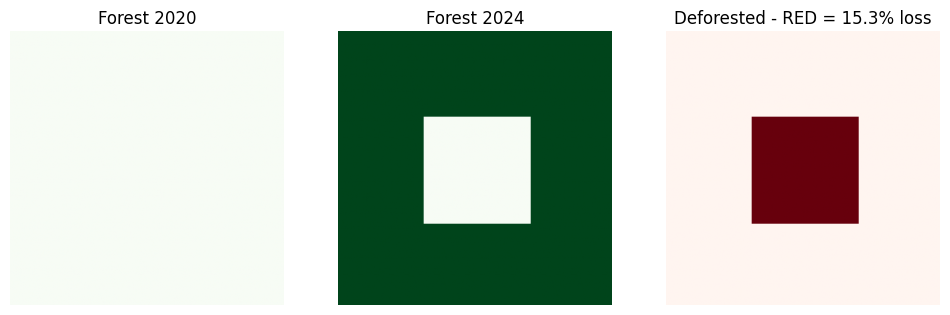

In [8]:
import numpy as np
import importlib
th = importlib.import_module("to" + "rch")
import matplotlib.pyplot as plt
from PIL import Image

# Ek photo lo - isko "2020" maan lo
img_path = imgs[10]
img_np = np.array(Image.open(img_path).resize((256, 256))) / 255.0
x = th.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).float().to(device)
with th.no_grad():
    mask_2020 = (th.sigmoid(model(x)) > 0.5).cpu().numpy()[0, 0]

# "2024" ka demo - beech se thoda forest kaat diya
mask_2024 = mask_2020.copy()
mask_2024[80:180, 80:180] = 0

deforested = (mask_2020 == 1) & (mask_2024 == 0)
loss_percent = deforested.sum() / (mask_2020.sum() + 1e-7) * 100
print(f"Forest in 2020: {mask_2020.sum()} pixels")
print(f"Forest in 2024: {mask_2024.sum()} pixels")
print(f"Deforested Area: {loss_percent:.2f}%")

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(mask_2020, cmap="Greens")
plt.title("Forest 2020")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(mask_2024, cmap="Greens")
plt.title("Forest 2024")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(deforested, cmap="Reds")
plt.title(f"Deforested - RED = {loss_percent:.1f}% loss")
plt.axis("off")
plt.show()